# Research question 2 — How do negative relationships evolve?

A link from one subreddit to another is a directed interaction. For established pairs, we compare a **first observed negative link** with a non-negative link selected at a similar stage in recorded pair history. We ask two questions: does the target link back, and what is the sentiment of its first link back? We then look at whether negativity in active relationships appears in one or both directions. This is the **evolution** chapter of the project; the origin of negativity and attention from third communities are studied separately.

We call a link *negative* when `LINK_SENTIMENT = -1`. The `+1` label combines neutral and positive links, so we call it *non-negative*. A negative link is not proof of an attack, and a negative link back is only a possible response, not proof of retaliation.

## 1. Imports and data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.max_columns", 20)

The notebook expects the two downloaded SNAP files in `data/raw/` and runs from the `ada_project` repository root. We load only the fields needed for this question.

In [2]:
data_dir = Path("data/raw")
columns = ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP", "LINK_SENTIMENT"]
files = {"body": data_dir / "soc-redditHyperlinks-body.tsv",
         "title": data_dir / "soc-redditHyperlinks-title.tsv"}
for path in files.values():
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. See dataset_information.md for download instructions.")

parts = []
for location, path in files.items():
    part = pd.read_csv(path, sep="	", usecols=columns)
    part["LOCATION"] = location
    parts.append(part)
links = pd.concat(parts, ignore_index=True)
print(f"Loaded {len(links):,} links: {len(parts[0]):,} body and {len(parts[1]):,} title")

Loaded 858,488 links: 286,561 body and 571,927 title


### Data checks and preparation

In [3]:
print("Missing values by column:")
display(links.isna().sum().to_frame("missing"))
print("Sentiment labels:", links["LINK_SENTIMENT"].value_counts().to_dict())
print("Duplicate rows:", links.duplicated().sum())
print("Self-links:", (links["SOURCE_SUBREDDIT"] == links["TARGET_SUBREDDIT"]).sum())

assert not links[columns].isna().any().any()
assert set(links["LINK_SENTIMENT"]) == {-1, 1}
assert not links.duplicated().any()

Missing values by column:


,missing
SOURCE_SUBREDDIT,0
TARGET_SUBREDDIT,0
POST_ID,0
TIMESTAMP,0
LINK_SENTIMENT,0
LOCATION,0


Sentiment labels: {1: 776278, -1: 82210}
Duplicate rows: 0
Self-links: 0


In [4]:
links["time"] = pd.to_datetime(links["TIMESTAMP"], errors="coerce")
assert links["time"].notna().all()
links = links.loc[links["SOURCE_SUBREDDIT"] != links["TARGET_SUBREDDIT"]].copy()
links = links.sort_values(["time", "POST_ID", "LOCATION"]).reset_index(drop=True)

# One unordered key identifies a relationship; source and target preserve its direction.
links["pair_a"] = np.minimum(links["SOURCE_SUBREDDIT"], links["TARGET_SUBREDDIT"])
links["pair_b"] = np.maximum(links["SOURCE_SUBREDDIT"], links["TARGET_SUBREDDIT"])
print(f"{len(links):,} usable links in {links.groupby(['pair_a', 'pair_b']).ngroups:,} pairs")
print(f"Observed period: {links['time'].min()} to {links['time'].max()}")

858,488 usable links in 309,667 pairs
Observed period: 2013-12-31 16:20:20 to 2017-04-30 16:58:21


## 2. Select comparable points in pair histories

We use 2014 to observe earlier links. For each pair, we select its **first eligible link from 2015 onward** after at least one recorded non-negative link and no recorded negative link. A negative selected link is therefore the first negative link **we observe** in an established pair. Non-negative selected links form a comparison group at the same stage of recorded history. We retain only links with a complete 30-day follow-up. The groups can still differ in activity and other ways.

In [5]:
pair = links.groupby(["pair_a", "pair_b"], sort=False)
links["earlier_links"] = pair.cumcount()
links["earlier_same_direction"] = links.groupby(
    ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"], sort=False).cumcount()
links["earlier_reverse_links"] = links["earlier_links"] - links["earlier_same_direction"]
is_negative = links["LINK_SENTIMENT"].eq(-1)
links["earlier_negative"] = is_negative.groupby([links["pair_a"], links["pair_b"]]).cumsum() - is_negative.astype(int)

analysis_start = pd.Timestamp("2015-01-01")
follow_up = pd.Timedelta(30, unit="D")
eligible = links.loc[
    links["time"].between(analysis_start, links["time"].max() - follow_up)
    & links["earlier_links"].ge(1)
    & links["earlier_negative"].eq(0)
]
events = eligible.drop_duplicates(["pair_a", "pair_b"]).copy()
events["negative_event"] = events["LINK_SENTIMENT"].eq(-1)
events["prior_reverse"] = events["earlier_reverse_links"].gt(0)
events["group"] = events["negative_event"].map({False: "Non-negative", True: "Negative"})
display(events.groupby("group").agg(pairs=("POST_ID", "size"),
                                     median_earlier_links=("earlier_links", "median"),
                                     prior_reverse_share=("prior_reverse", "mean"))
        .style.format({"prior_reverse_share": "{:.1%}"}))

,pairs,median_earlier_links,prior_reverse_share
group,,,
Negative,5081,1.000000,15.5%
Non-negative,66030,1.000000,26.0%


Prior reciprocity already differs between the groups: the target had linked to the source before in **15.5%** of negative-event pairs and **26.0%** of non-negative-event pairs. We account for this observed difference in the adjusted check below.

## 3. Does the pair interact again?

We first measure any subsequent link in the pair. To find a response, we also search for the **first reverse-direction link**, allowing other links in the original direction to occur in between. A reverse link counts only when it arrives within 30 days.

In [6]:
# The next link in either direction is adjacent within the sorted pair history.
links["next_pair_time"] = pair["time"].shift(-1)
events["next_pair_time"] = links.loc[events.index, "next_pair_time"].to_numpy()
events["another_link_30d"] = (events["next_pair_time"] - events["time"]).le(follow_up)

# Swap source and target on the right to find the next link in the reverse direction.
reverse_links = links[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "time", "LINK_SENTIMENT"]].rename(
    columns={"SOURCE_SUBREDDIT": "TARGET_SUBREDDIT",
             "TARGET_SUBREDDIT": "SOURCE_SUBREDDIT",
             "time": "reverse_time", "LINK_SENTIMENT": "reverse_sentiment"})
event_lookup = events[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "time"]].copy()
event_lookup["event_id"] = event_lookup.index
matched = pd.merge_asof(
    event_lookup.sort_values("time"),
    reverse_links.sort_values("reverse_time"),
    left_on="time", right_on="reverse_time",
    by=["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"],
    direction="forward", allow_exact_matches=False,
)
matched = matched.set_index("event_id")
events["reverse_time"] = matched["reverse_time"]
events["reverse_sentiment"] = matched["reverse_sentiment"]
events["reverse_30d"] = (events["reverse_time"] - events["time"]).le(follow_up)
events["negative_reverse_30d"] = events["reverse_30d"] & events["reverse_sentiment"].eq(-1)

In [7]:
response = events.groupby("group").agg(
    pairs=("POST_ID", "size"),
    another_link_30d=("another_link_30d", "sum"),
    reverse_30d=("reverse_30d", "sum"),
    negative_reverse_30d=("negative_reverse_30d", "sum"),
).reindex(["Non-negative", "Negative"])
response["another_link_rate"] = response["another_link_30d"] / response["pairs"]
response["reverse_rate"] = response["reverse_30d"] / response["pairs"]
response["negative_given_reverse"] = response["negative_reverse_30d"] / response["reverse_30d"]
display(response.style.format({"another_link_rate": "{:.1%}", "reverse_rate": "{:.1%}",
                               "negative_given_reverse": "{:.1%}"}))

,pairs,another_link_30d,reverse_30d,negative_reverse_30d,another_link_rate,reverse_rate,negative_given_reverse
group,,,,,,,
Non-negative,66030,14278,3983,143,21.6%,6.0%,3.6%
Negative,5081,1000,168,27,19.7%,3.3%,16.1%


The two panels use different denominators. The first asks how often any reverse link appears among all selected pairs. The second asks about sentiment **only among pairs that link back**. Error bars are 95% Wilson intervals for each observed proportion.

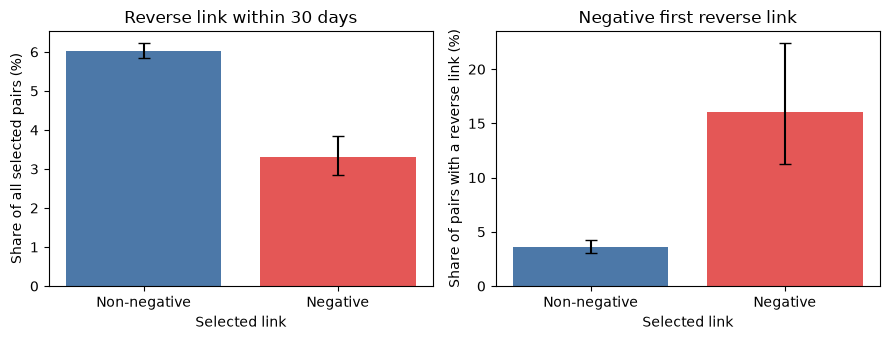

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
comparisons = [("reverse_30d", "pairs", "Reverse link within 30 days",
                "Share of all selected pairs (%)"),
               ("negative_reverse_30d", "reverse_30d", "Negative first reverse link",
                "Share of pairs with a reverse link (%)")]
for ax, (numerator, denominator, title, ylabel) in zip(axes, comparisons):
    successes = response[numerator].to_numpy()
    totals = response[denominator].to_numpy()
    rates = successes / totals
    lower, upper = proportion_confint(successes, totals, method="wilson")
    ax.bar(response.index, rates * 100, color=["#4C78A8", "#E45756"])
    ax.errorbar(range(2), rates * 100,
                yerr=[(rates - lower) * 100, (upper - rates) * 100],
                fmt="none", color="black", capsize=4)
    ax.set(title=title, ylabel=ylabel, xlabel="Selected link")
fig.tight_layout()
plt.show()

A reverse link arrives within 30 days for **168 of 5,081 pairs (3.3%)** whose selected link is negative, compared with **3,983 of 66,030 pairs (6.0%)** whose selected link is non-negative. Among those that link back, the first reverse link is negative for **27 of 168 (16.1%)** versus **143 of 3,983 (3.6%)**. Thus fewer negative-event pairs link back, but the pairs that do are more likely to link back negatively. Across *all* selected pairs, a negative reverse link is rare: 27/5,081 (0.53%) versus 143/66,030 (0.22%).

### Check: does earlier pair activity explain the difference?

Pairs with more recorded links have more opportunities to link back. We therefore repeat the comparison within three simple groups based on the number of links **before** the selected event. This is a descriptive check, not a matched experiment.

In [9]:
events["earlier_activity"] = pd.cut(events["earlier_links"],
                                     bins=[0, 1, 4, np.inf], labels=["1", "2–4", "5+"])
by_activity = events.groupby(["earlier_activity", "group"], observed=True).agg(
    pairs=("POST_ID", "size"),
    reverse_30d=("reverse_30d", "sum"),
    negative_reverse_30d=("negative_reverse_30d", "sum"),
)
by_activity["reverse_rate"] = by_activity["reverse_30d"] / by_activity["pairs"]
by_activity["negative_given_reverse"] = (
    by_activity["negative_reverse_30d"] / by_activity["reverse_30d"]
)
display(by_activity.style.format({"reverse_rate": "{:.1%}",
                                  "negative_given_reverse": "{:.1%}"}))

The lower reverse-link rate after a negative event appears in all three activity groups. The conditional negative share is also higher in each group, but in the `5+` group it rests on only **one** negative reverse link after a negative event. These strata show the raw pattern is not solely driven by the simplest measure of earlier pair activity.

### Does the pattern depend on the time window?

In [10]:
windows = []
for days in [7, 30]:
    reverse = (events["reverse_time"] - events["time"]).le(pd.Timedelta(days, unit="D"))
    for group, subset in events.groupby("group"):
        came_back = reverse.loc[subset.index]
        negative_back = came_back & subset["reverse_sentiment"].eq(-1)
        windows.append({"days": days, "group": group, "pairs": len(subset),
                        "reverse": came_back.sum(), "negative_reverse": negative_back.sum(),
                        "reverse_rate": came_back.mean(),
                        "negative_given_reverse": negative_back.sum() / came_back.sum()})
window_table = pd.DataFrame(windows).set_index(["days", "group"])
display(window_table.style.format({"reverse_rate": "{:.1%}",
                                   "negative_given_reverse": "{:.1%}"}))

The pattern is visible within a week as well: reverse links are less frequent after negative selected links (1.5% versus 2.7%), while negative sentiment among those reverse links is more frequent (14.3% versus 3.6%). The seven-day negative group contains only 77 reverse links, so its conditional percentage is less precise.

### Adjustment for observed pair history and calendar time

We fit two small logistic models: one for a reverse link within 30 days among **all** selected pairs, and one for a negative first reverse link among **responders**. Each includes the selected link's sentiment, the number of earlier pair links, whether the target had linked to the source before, year, and title/body location. Standard errors are clustered by target subreddit because many pairs share a target. The models are a sensitivity check, not a causal estimate.

In [11]:
events["negative_link"] = events["negative_event"].astype(int)
events["year"] = events["time"].dt.year.astype(str)
events["reverse_outcome"] = events["reverse_30d"].astype(int)
events["negative_reverse_outcome"] = events["negative_reverse_30d"].astype(int)
formula = "OUTCOME ~ negative_link + np.log1p(earlier_links) + prior_reverse + C(year) + C(LOCATION)"
models = []
for label, sample, outcome in [
    ("Any reverse link", events, "reverse_outcome"),
    ("Negative if reversed", events.loc[events["reverse_30d"]], "negative_reverse_outcome")
]:
    model = smf.logit(formula.replace("OUTCOME", outcome), data=sample).fit(
        disp=False, cov_type="cluster", cov_kwds={"groups": sample["TARGET_SUBREDDIT"]})
    low, high = model.conf_int().loc["negative_link"]
    models.append({"outcome": label, "observations": len(sample),
                   "odds_ratio": np.exp(model.params["negative_link"]),
                   "ci_low": np.exp(low), "ci_high": np.exp(high),
                   "p_value": model.pvalues["negative_link"]})
model_table = pd.DataFrame(models).set_index("outcome")
display(model_table.style.format({"odds_ratio": "{:.2f}", "ci_low": "{:.2f}",
                                  "ci_high": "{:.2f}", "p_value": "{:.3g}"}))

,observations,odds_ratio,ci_low,ci_high,p_value
outcome,,,,,
Any reverse link,71111,0.66,0.56,0.78,7.45e-07
Negative if reversed,4151,5.01,3.18,7.88,3.1e-12


After these adjustments, a negative selected link is associated with lower odds of a reverse link (odds ratio **0.66**, 95% CI 0.56–0.78). Among pairs that link back, it is associated with higher odds that the first reverse link is negative (odds ratio **5.01**, 95% CI 3.18–7.88). These are associations: the second model selects only pairs that responded, and neither model removes unobserved differences between pairs.

### One observed pair, as a timeline

The plot below is a concrete example of the sequence we measure. We select a pair with a negative first reverse link so both parts of the question are visible. It illustrates the definition; it is not selected as a representative pair.

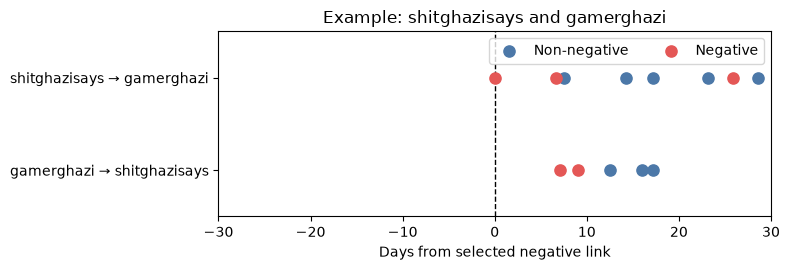

In [12]:
returned = events.loc[events["reverse_30d"]].copy()
example = returned.loc[returned["negative_event"] & returned["negative_reverse_30d"]].sort_values(
    ["time", "pair_a", "pair_b"]).iloc[0]
example_links = links.loc[
    links["pair_a"].eq(example["pair_a"]) & links["pair_b"].eq(example["pair_b"])
    & links["time"].between(example["time"] - follow_up, example["time"] + follow_up)
].copy()
example_links["days_from_event"] = (
    example_links["time"] - example["time"]).dt.total_seconds() / 86400
example_links["direction"] = np.where(
    example_links["SOURCE_SUBREDDIT"].eq(example["SOURCE_SUBREDDIT"]), 1, 0)

fig, ax = plt.subplots(figsize=(8, 2.8))
for sentiment, color, label in [(1, "#4C78A8", "Non-negative"),
                                (-1, "#E45756", "Negative")]:
    part = example_links.loc[example_links["LINK_SENTIMENT"].eq(sentiment)]
    ax.scatter(part["days_from_event"], part["direction"],
               s=65, color=color, label=label, zorder=3)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(xlim=(-30, 30), ylim=(-0.5, 1.5), xlabel="Days from selected negative link",
       title=f"Example: {example['SOURCE_SUBREDDIT']} and {example['TARGET_SUBREDDIT']}")
ax.set_yticks([0, 1], [f"{example['TARGET_SUBREDDIT']} → {example['SOURCE_SUBREDDIT']}",
                        f"{example['SOURCE_SUBREDDIT']} → {example['TARGET_SUBREDDIT']}"])
ax.legend(loc="upper right", ncol=2)
fig.tight_layout()
plt.show()

## 4. Separate full-history view: is negativity mutual?

This second view describes **full observed pair histories**, rather than the 30-day event sample. We keep pairs with at least five links in **each** direction. We classify a direction as negative when it has at least two negative links **and** at least 20% of its recorded links are negative. These cutoffs are descriptive choices, not natural boundaries.

In [13]:
directions = links.groupby(["pair_a", "pair_b", "SOURCE_SUBREDDIT"]).agg(
    links=("LINK_SENTIMENT", "size"),
    negative_links=("LINK_SENTIMENT", lambda x: x.eq(-1).sum()),
).reset_index()
directions["negative_share"] = directions["negative_links"] / directions["links"]
active = directions.loc[directions["links"].ge(5)].copy()
active["negative_direction"] = active["negative_links"].ge(2) & active["negative_share"].ge(0.20)
pairs_both = active.groupby(["pair_a", "pair_b"]).filter(lambda x: len(x) == 2)
pair_types = pairs_both.groupby(["pair_a", "pair_b"])["negative_direction"].sum().map(
    {0: "Neither direction", 1: "One direction", 2: "Both directions"})
counts = pair_types.value_counts().reindex(
    ["Neither direction", "One direction", "Both directions"], fill_value=0)
print(f"Active reciprocal pairs: {len(pair_types):,}")
display(pd.DataFrame({"pairs": counts, "share": counts / counts.sum()}).style.format({"share": "{:.1%}"}))

Active reciprocal pairs: 3,410


,pairs,share
negative_direction,,
Neither direction,3022,88.6%
One direction,284,8.3%
Both directions,104,3.0%


## 5. Takeaway and limits

The event analysis suggests two different responses to a first *observed* negative link: most pairs do not link back within a month, but a negative first link back is more common among the few that do. The difference remains visible in a seven-day window and after a limited adjustment for recorded pair activity, prior reciprocity, year, and link location.

In the full histories of **3,410** active reciprocal pairs, negativity that meets our minimum count and 20% share cutoffs appears more often in one direction than in both. This longer-history view describes a different sample from the event comparison, and the cutoffs are choices for summarizing it.

These patterns are descriptive. The data begin around 2014, so earlier interactions are unseen. Active pairs have more chances to produce a response, the sentiment labels are classifier outputs, and the two event groups may differ before the selected link. Nothing here establishes that a link caused a reply or a change in sentiment. A later analysis can compare pairs with similar prior activity and calendar periods.